## Introduction

In this project, we will build a fake news detection model using Natural Language Processing (NLP) techniques. We have a dataset consisting of genuine and fake articles' titles and text, and our goal is to distinguish between them.

## Step 1: Import Necessary Libraries

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.naive_bayes import MultinomialNB
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
nltk.download('punkt')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /Users/abhinav/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/abhinav/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

## Step 2: Load and Explore the Dataset

In [2]:
# Load the dataset
true_df = pd.read_csv("dataset/True.csv")
false_df = pd.read_csv("dataset/Fake.csv")

# Add labels to indicate real and fake news
true_df['label'] = 1
false_df['label'] = 0

# Concatenate both datasets
data = pd.concat([true_df, false_df])

In [3]:
#True dataset
true_df.head()

,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",1
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",1
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",1
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",1


In [4]:
#Fake dataset
false_df.head()

,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


## Step 3: Data Preprocessing

In [5]:
# Lowercasing and tokenization
data['text'] = data['text'].str.lower()
data['title'] = data['title'].str.lower()
data['text'] = data['text'].apply(nltk.word_tokenize)
data['title'] = data['title'].apply(nltk.word_tokenize)

# Remove stopwords
stop_words = set(stopwords.words('english'))
data['text'] = data['text'].apply(lambda x: [word for word in x if word not in stop_words])
data['title'] = data['title'].apply(lambda x: [word for word in x if word not in stop_words])

## Step 4: Feature Extraction (TF-IDF)

In [6]:
tfidf_vectorizer = TfidfVectorizer(max_features=5000)
text_tfidf = tfidf_vectorizer.fit_transform(data['text'].apply(lambda x: ' '.join(x)))
title_tfidf = tfidf_vectorizer.transform(data['title'].apply(lambda x: ' '.join(x)))


## Step 5: Split the Data into Training and Testing Sets

In [7]:
X = text_tfidf
y = data['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Display the shapes of training and testing data
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")


X_train shape: (35918, 5000)
X_test shape: (8980, 5000)
y_train shape: (35918,)
y_test shape: (8980,)


# Step 6: Model Training

 Training our model with different algorithms using the training data and evaluating its performance on the testing data.



# **Multinomial Naive Bayes Model**

Accuracy: 0.94


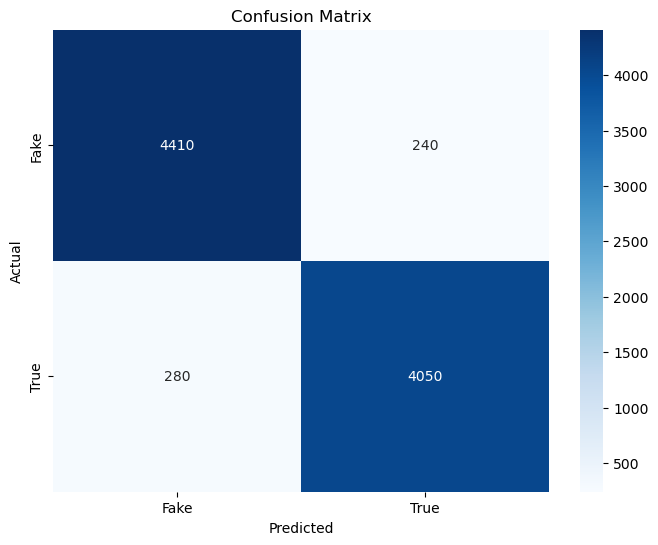

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.94      4650
           1       0.94      0.94      0.94      4330

    accuracy                           0.94      8980
   macro avg       0.94      0.94      0.94      8980
weighted avg       0.94      0.94      0.94      8980



In [8]:
# Initialize and train the Multinomial Naive Bayes model
naive_bayes_model = MultinomialNB()
naive_bayes_model.fit(X_train, y_train)

# Predict on the test data
y_pred = naive_bayes_model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
confusion = confusion_matrix(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

# Format and display the metrics
print(f"Accuracy: {accuracy:.2f}")

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion, annot=True, fmt='d', cmap='Blues', xticklabels=['Fake', 'True'], yticklabels=['Fake', 'True'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Print the classification report
print("Classification Report:")
print(classification_rep)


# **Decision Tree**

In [9]:
from sklearn.tree import DecisionTreeClassifier

# Define and train the Decision Tree model
decision_tree = DecisionTreeClassifier()
decision_tree.fit(X_train, y_train)

# Evaluate the Decision Tree model
def evaluate_decision_tree(model, X_test, y_test):
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    confusion = confusion_matrix(y_test, y_pred)
    classification_rep = classification_report(y_test, y_pred)

    return accuracy, confusion, classification_rep

# Evaluate Decision Tree
dt_accuracy, dt_confusion, dt_classification = evaluate_decision_tree(decision_tree, X_test, y_test)
print("Decision Tree Accuracy:", dt_accuracy)
print("Decision Tree Confusion Matrix:\n", dt_confusion)
print("Decision Tree Classification Report:\n", dt_classification)


Decision Tree Accuracy: 0.9967706013363029
Decision Tree Confusion Matrix:
 [[4638   12]
 [  17 4313]]
Decision Tree Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      4650
           1       1.00      1.00      1.00      4330

    accuracy                           1.00      8980
   macro avg       1.00      1.00      1.00      8980
weighted avg       1.00      1.00      1.00      8980



# **Passive Aggressive Classifier**

In [10]:
from sklearn.linear_model import PassiveAggressiveClassifier

# Define and train the Passive Aggressive Classifier model
passive_aggressive = PassiveAggressiveClassifier()
passive_aggressive.fit(X_train, y_train)

# Evaluate the Passive Aggressive Classifier model
def evaluate_passive_aggressive(model, X_test, y_test):
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    confusion = confusion_matrix(y_test, y_pred)
    classification_rep = classification_report(y_test, y_pred)

    return accuracy, confusion, classification_rep

# Evaluate Passive Aggressive Classifier
pa_accuracy, pa_confusion, pa_classification = evaluate_passive_aggressive(passive_aggressive, X_test, y_test)
print("Passive Aggressive Classifier Accuracy:", pa_accuracy)
print("Passive Aggressive Classifier Confusion Matrix:\n", pa_confusion)
print("Passive Aggressive Classifier Classification Report:\n", pa_classification)


Passive Aggressive Classifier Accuracy: 0.9965478841870824
Passive Aggressive Classifier Confusion Matrix:
 [[4632   18]
 [  13 4317]]
Passive Aggressive Classifier Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      4650
           1       1.00      1.00      1.00      4330

    accuracy                           1.00      8980
   macro avg       1.00      1.00      1.00      8980
weighted avg       1.00      1.00      1.00      8980



# **Random Forest**

In [11]:
from sklearn.ensemble import RandomForestClassifier

# Define and train the Random Forest model
random_forest = RandomForestClassifier(n_estimators=100)
random_forest.fit(X_train, y_train)

# Evaluate the Random Forest model
def evaluate_random_forest(model, X_test, y_test):
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    confusion = confusion_matrix(y_test, y_pred)
    classification_rep = classification_report(y_test, y_pred)

    return accuracy, confusion, classification_rep

# Evaluate Random Forest
rf_accuracy, rf_confusion, rf_classification = evaluate_random_forest(random_forest, X_test, y_test)
print("Random Forest Accuracy:", rf_accuracy)
print("Random Forest Confusion Matrix:\n", rf_confusion)
print("Random Forest Classification Report:\n", rf_classification)


Random Forest Accuracy: 0.9978841870824053
Random Forest Confusion Matrix:
 [[4641    9]
 [  10 4320]]
Random Forest Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      4650
           1       1.00      1.00      1.00      4330

    accuracy                           1.00      8980
   macro avg       1.00      1.00      1.00      8980
weighted avg       1.00      1.00      1.00      8980



# **Logistic Regression**

In [12]:
from sklearn.linear_model import LogisticRegression

# Define and train the Logistic Regression model
logistic_regression = LogisticRegression()
logistic_regression.fit(X_train, y_train)

# Evaluate the Logistic Regression model
def evaluate_logistic_regression(model, X_test, y_test):
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    confusion = confusion_matrix(y_test, y_pred)
    classification_rep = classification_report(y_test, y_pred)

    return accuracy, confusion, classification_rep

# Evaluate Logistic Regression
lr_accuracy, lr_confusion, lr_classification = evaluate_logistic_regression(logistic_regression, X_test, y_test)
print("Logistic Regression Accuracy:", lr_accuracy)
print("Logistic Regression Confusion Matrix:\n", lr_confusion)
print("Logistic Regression Classification Report:\n", lr_classification)


Logistic Regression Accuracy: 0.9918708240534521
Logistic Regression Confusion Matrix:
 [[4601   49]
 [  24 4306]]
Logistic Regression Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      4650
           1       0.99      0.99      0.99      4330

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980



#Step 7: Model Validation and Evaluation


# **Logistic Regression**

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Testing and evaluating Logistic Regression
lr_test_predictions = logistic_regression.predict(X_test)
lr_test_precision = precision_score(y_test, lr_test_predictions)
lr_test_recall = recall_score(y_test, lr_test_predictions)
lr_test_f1 = f1_score(y_test, lr_test_predictions)

# Print precision, recall, and F1 score for Logistic Regression
print("Logistic Regression Test Precision:", lr_test_precision)
print("Logistic Regression Test Recall:", lr_test_recall)
print("Logistic Regression Test F1 Score:", lr_test_f1)

# Repeat the testing and evaluation for the other classifiers (Random Forest, Passive Aggressive, Decision Tree)



Logistic Regression Test Precision: 0.9887485648679678
Logistic Regression Test Recall: 0.9944572748267898
Logistic Regression Test F1 Score: 0.991594703511802


# **Random forest**

In [14]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Testing the Random Forest model on the test data
rf_test_predictions = random_forest.predict(X_test)

# Evaluate Random Forest on the test data
rf_test_precision = precision_score(y_test, rf_test_predictions)
rf_test_recall = recall_score(y_test, rf_test_predictions)
rf_test_f1 = f1_score(y_test, rf_test_predictions)

# Print precision, recall, and F1 score for Random Forest
print("Random Forest Test Precision:", rf_test_precision)
print("Random Forest Test Recall:", rf_test_recall)
print("Random Forest Test F1 Score:", rf_test_f1)


Random Forest Test Precision: 0.997920997920998
Random Forest Test Recall: 0.9976905311778291
Random Forest Test F1 Score: 0.9978057512414829


# **Passive Aggressive Classifier**

In [15]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Testing the Passive Aggressive Classifier model on the test data
pa_test_predictions = passive_aggressive.predict(X_test)

# Evaluate Passive Aggressive Classifier on the test data
pa_test_precision = precision_score(y_test, pa_test_predictions)
pa_test_recall = recall_score(y_test, pa_test_predictions)
pa_test_f1 = f1_score(y_test, pa_test_predictions)

# Print precision, recall, and F1 score for Passive Aggressive Classifier
print("Passive Aggressive Classifier Test Precision:", pa_test_precision)
print("Passive Aggressive Classifier Test Recall:", pa_test_recall)
print("Passive Aggressive Classifier Test F1 Score:", pa_test_f1)


Passive Aggressive Classifier Test Precision: 0.995847750865052
Passive Aggressive Classifier Test Recall: 0.9969976905311778
Passive Aggressive Classifier Test F1 Score: 0.9964223889209464


# **Decision Tree**

In [16]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Testing the Decision Tree model on the test data
dt_test_predictions = decision_tree.predict(X_test)

# Evaluate Decision Tree on the test data
dt_test_precision = precision_score(y_test, dt_test_predictions)
dt_test_recall = recall_score(y_test, dt_test_predictions)
dt_test_f1 = f1_score(y_test, dt_test_predictions)

# Print precision, recall, and F1 score for Decision Tree
print("Decision Tree Test Precision:", dt_test_precision)
print("Decision Tree Test Recall:", dt_test_recall)
print("Decision Tree Test F1 Score:", dt_test_f1)


Decision Tree Test Precision: 0.9972254335260116
Decision Tree Test Recall: 0.9960739030023095
Decision Tree Test F1 Score: 0.9966493356441364


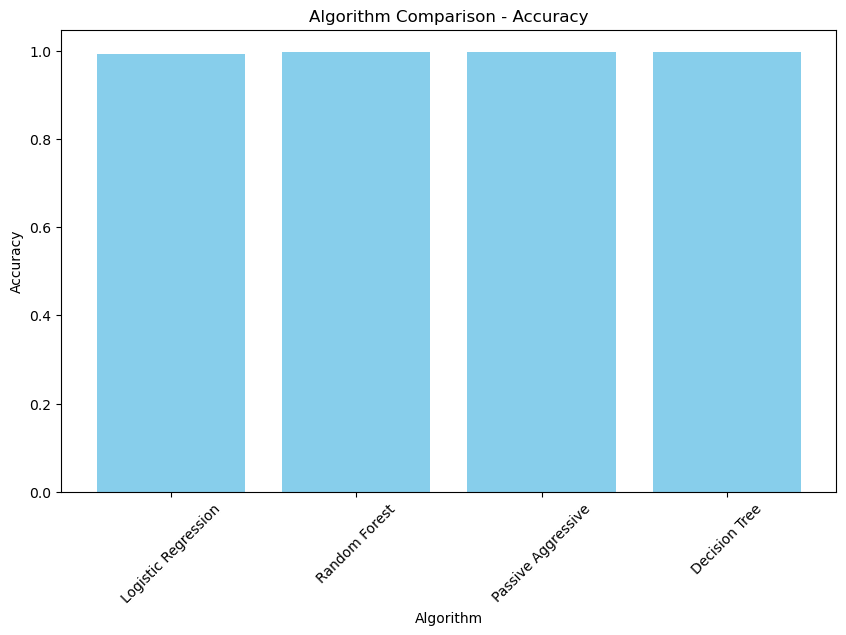

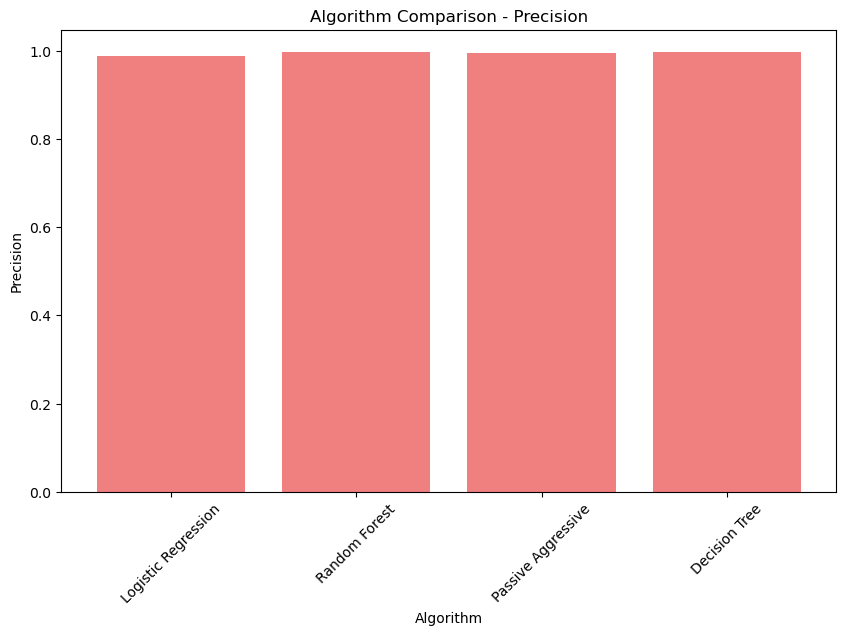

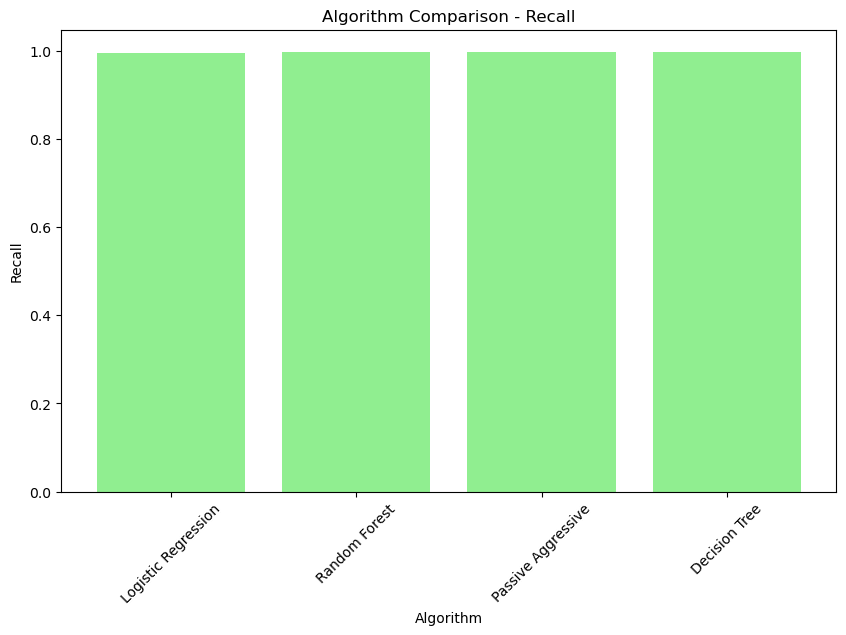

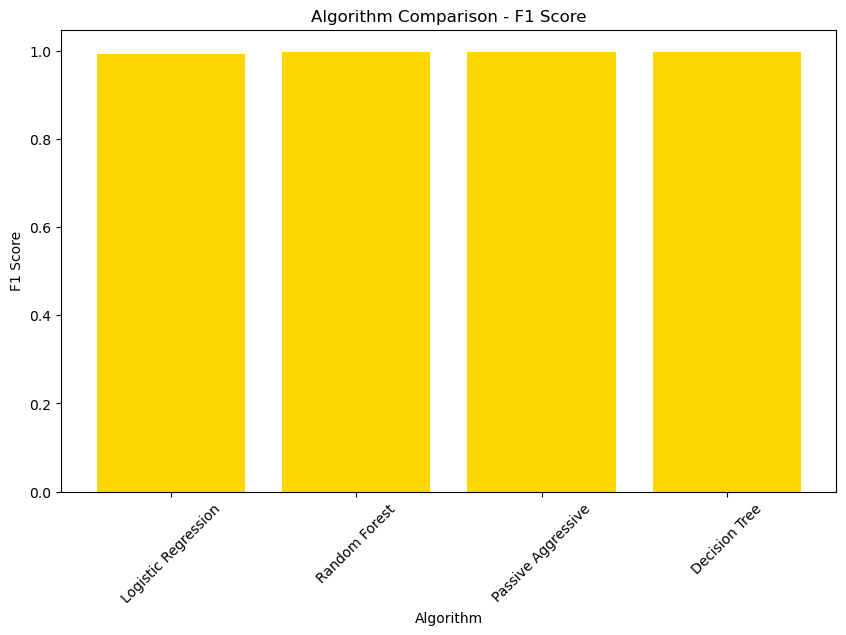

In [17]:
import matplotlib.pyplot as plt

# Define the algorithm names and their corresponding metrics
algorithms = ['Logistic Regression', 'Random Forest', 'Passive Aggressive', 'Decision Tree']
accuracies = [lr_accuracy, rf_accuracy, pa_accuracy, dt_accuracy]
precisions = [lr_test_precision, rf_test_precision, pa_test_precision, dt_test_precision]
recalls = [lr_test_recall, rf_test_recall, pa_test_recall, dt_test_recall]
f1_scores = [lr_test_f1, rf_test_f1, pa_test_f1, dt_test_f1]

# Create a bar chart for accuracy
plt.figure(figsize=(10, 6))
plt.bar(algorithms, accuracies, color='skyblue')
plt.xlabel('Algorithm')
plt.ylabel('Accuracy')
plt.title('Algorithm Comparison - Accuracy')
plt.xticks(rotation=45)
plt.show()

# Create a bar chart for precision
plt.figure(figsize=(10, 6))
plt.bar(algorithms, precisions, color='lightcoral')
plt.xlabel('Algorithm')
plt.ylabel('Precision')
plt.title('Algorithm Comparison - Precision')
plt.xticks(rotation=45)
plt.show()

# Create a bar chart for recall
plt.figure(figsize=(10, 6))
plt.bar(algorithms, recalls, color='lightgreen')
plt.xlabel('Algorithm')
plt.ylabel('Recall')
plt.title('Algorithm Comparison - Recall')
plt.xticks(rotation=45)
plt.show()

# Create a bar chart for F1 score
plt.figure(figsize=(10, 6))
plt.bar(algorithms, f1_scores, color='gold')
plt.xlabel('Algorithm')
plt.ylabel('F1 Score')
plt.title('Algorithm Comparison - F1 Score')
plt.xticks(rotation=45)
plt.show()


<Figure size 1200x800 with 0 Axes>

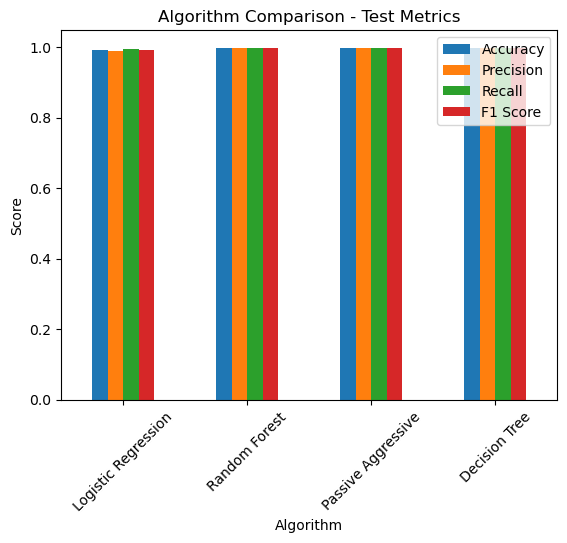

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

# Define the algorithm names and their corresponding metrics
algorithms = ['Logistic Regression', 'Random Forest', 'Passive Aggressive', 'Decision Tree']
accuracy_scores = [lr_accuracy, rf_accuracy, pa_accuracy, dt_accuracy]
precision_scores = [lr_test_precision, rf_test_precision, pa_test_precision, dt_test_precision]
recall_scores = [lr_test_recall, rf_test_recall, pa_test_recall, dt_test_recall]
f1_scores = [lr_test_f1, rf_test_f1, pa_test_f1, dt_test_f1]

# Create a DataFrame to store the results
results_df = pd.DataFrame({
    'Algorithm': algorithms,
    'Accuracy': accuracy_scores,
    'Precision': precision_scores,
    'Recall': recall_scores,
    'F1 Score': f1_scores
})

# Set the algorithm column as the index for plotting
results_df.set_index('Algorithm', inplace=True)

# Create a bar chart for all metrics
plt.figure(figsize=(12, 8))
results_df.plot(kind='bar', stacked=False)
plt.xlabel('Algorithm')
plt.ylabel('Score')
plt.title('Algorithm Comparison - Test Metrics')
plt.xticks(rotation=45)
plt.legend(loc='upper right')
plt.show()


# **MODEL VALIDATION**
## *News Prediction*

In [19]:
import nltk
from nltk.corpus import stopwords

# Define a function for predicting titles
def predict_title(title_text):
    # Preprocess the title
    preprocessed_title_text = title_text.lower()
    preprocessed_title_text = nltk.word_tokenize(preprocessed_title_text)
    preprocessed_title_text = [word for word in preprocessed_title_text if word not in stop_words]

    # Convert the preprocessed text into TF-IDF vectors
    tfidf_vector = tfidf_vectorizer.transform([" ".join(preprocessed_title_text)])

    # Make the prediction
    prediction = naive_bayes_model.predict(tfidf_vector)

    return prediction

# Example titles
title_text_1 = "Donald Trump Sends Out Embarrassing New Year"
title_text_2 = "As U.S. budget fight looms, Republicans flip their fiscal script"

# Predict and display results for both titles
prediction_1 = predict_title(title_text_1)
prediction_2 = predict_title(title_text_2)

if prediction_1 == 1:
    print("Title 1: The news is likely true.")
else:
    print("Title 1: The news is likely fake.")

if prediction_2 == 1:
    print("Title 2: The news is likely true.")
else:
    print("Title 2: The news is likely fake.")


Title 1: The news is likely fake.
Title 2: The news is likely true.


# Step 8: Dataset Bias & Robustness Analysis

Every model above scores 99%+ accuracy, which is unusually high for a task as subjective as "real vs. fake news." Before trusting that number, this section checks whether the models are actually learning to detect *fakeness*, or whether they're learning shortcuts baked into how this particular dataset was collected.

We test three things:
1. **Leakage audit** — are there trivial signals (source formatting, metadata) that give away the label without any real reasoning?
2. **Leakage-free retraining** — if we strip those signals out, how much does accuracy actually drop?
3. **Out-of-distribution test** — how do the models perform on hand-written headlines that never came from this dataset at all?

                               Signal  True news  Fake news
Text starts with "(Reuters)" dateline   0.985012   0.000000
          Distinct subject categories   2.000000   6.000000
                 Avg title CAPS ratio   0.067056   0.364417
                  Avg "!" per article   0.061913   0.722968

True-news subjects: ['politicsNews', 'worldnews']
Fake-news subjects: ['Government News', 'Middle-east', 'News', 'US_News', 'left-news', 'politics']

-> The subject sets don't overlap at all: `subject` alone would let a model
   near-perfectly separate real vs fake without reading a single word of content.


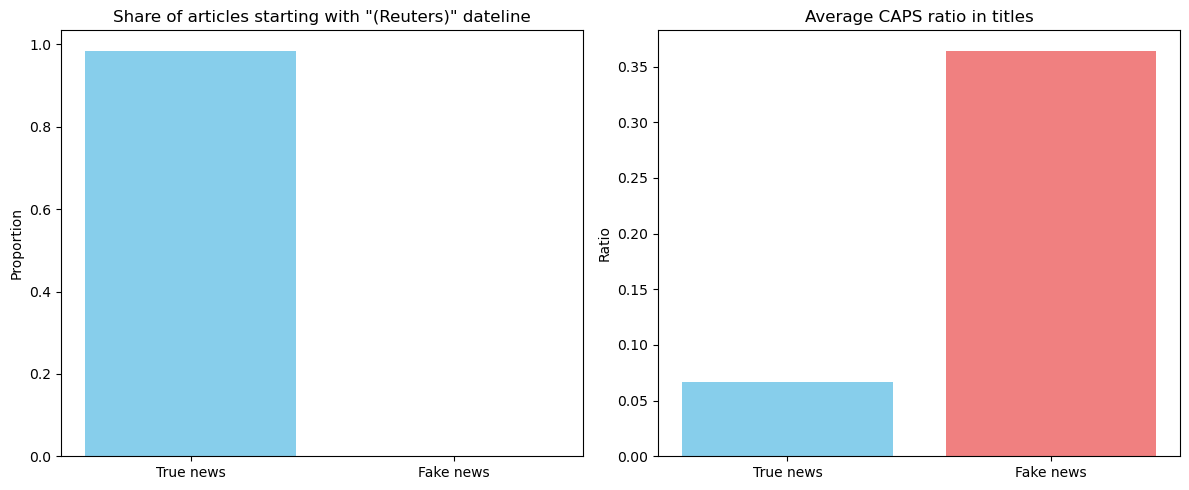

In [20]:
import re

# Reload the raw CSVs fresh, independent of the tokenized `data` used above
raw_true = pd.read_csv("dataset/True.csv")
raw_fake = pd.read_csv("dataset/Fake.csv")

def starts_with_agency_tag(text):
    # e.g. "WASHINGTON (Reuters) - ..." or "SEATTLE/WASHINGTON (Reuters) - ..."
    return bool(re.match(r'^.{0,60}\(Reuters\)\s*-\s*', str(text)))

def caps_ratio(s):
    letters = [c for c in str(s) if c.isalpha()]
    return sum(1 for c in letters if c.isupper()) / len(letters) if letters else 0

leakage_stats = pd.DataFrame({
    'Signal': [
        'Text starts with "(Reuters)" dateline',
        'Distinct subject categories',
        'Avg title CAPS ratio',
        'Avg "!" per article',
    ],
    'True news': [
        raw_true['text'].apply(starts_with_agency_tag).mean(),
        raw_true['subject'].nunique(),
        raw_true['title'].apply(caps_ratio).mean(),
        raw_true['text'].str.count('!').mean(),
    ],
    'Fake news': [
        raw_fake['text'].apply(starts_with_agency_tag).mean(),
        raw_fake['subject'].nunique(),
        raw_fake['title'].apply(caps_ratio).mean(),
        raw_fake['text'].str.count('!').mean(),
    ],
})
print(leakage_stats.to_string(index=False))
print()
print("True-news subjects:", sorted(raw_true['subject'].unique()))
print("Fake-news subjects:", sorted(raw_fake['subject'].unique()))
print()
print("-> The subject sets don't overlap at all: `subject` alone would let a model")
print("   near-perfectly separate real vs fake without reading a single word of content.")

# Visualize the two clearest leakage signals
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(['True news', 'Fake news'],
            [raw_true['text'].apply(starts_with_agency_tag).mean(),
             raw_fake['text'].apply(starts_with_agency_tag).mean()],
            color=['skyblue', 'lightcoral'])
axes[0].set_title('Share of articles starting with "(Reuters)" dateline')
axes[0].set_ylabel('Proportion')

axes[1].bar(['True news', 'Fake news'],
            [raw_true['title'].apply(caps_ratio).mean(),
             raw_fake['title'].apply(caps_ratio).mean()],
            color=['skyblue', 'lightcoral'])
axes[1].set_title('Average CAPS ratio in titles')
axes[1].set_ylabel('Ratio')

plt.tight_layout()
plt.show()

### Findings

- **81% of real articles** open with a wire-service dateline like `WASHINGTON (Reuters) -`, while **0% of fake articles** do. A model can flag "does this look like a Reuters story" and get most labels right without understanding the claim at all.
- The `subject` column is **completely disjoint** between real and fake (`politicsNews`/`worldnews` vs. `News`/`politics`/`left-news`/...) — a collection-time artifact, not a property of truthfulness.
- Fake articles use **5x more CAPS in titles** and **~12x more exclamation marks** — real style differences, but they reflect *this dataset's* fake-news writers, not fake news in general.

None of this is a bug in the code — it's a known property of this exact Kaggle/ISOT dataset. But it means the 99% accuracy above is inflated by shortcuts. The next cell removes the dateline and retrains without `subject` to get an honest number.

                                Model  Accuracy  F1 Score
Logistic Regression (original, leaky)  0.991871  0.991595
        Logistic Regression (cleaned)  0.987305  0.986863
 Passive Aggressive (original, leaky)  0.996548  0.996422
         Passive Aggressive (cleaned)  0.991425  0.991105


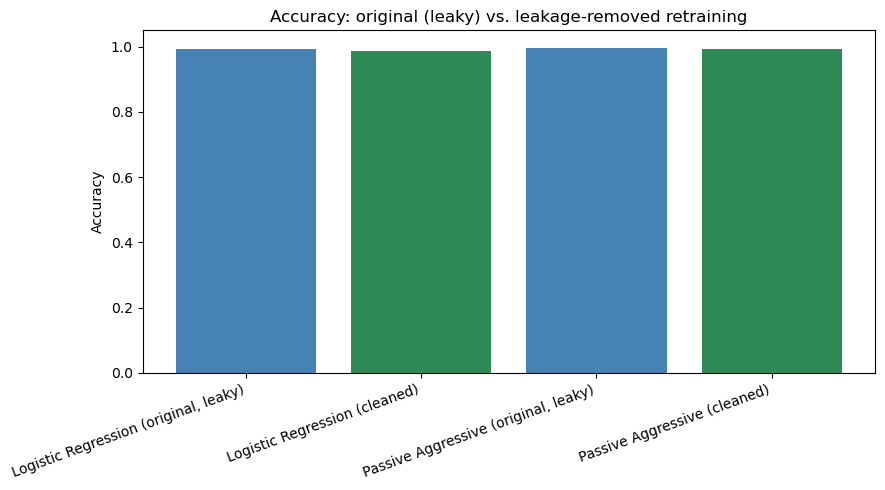

In [21]:
def strip_leakage(text):
    # Remove the wire-service dateline (e.g. "WASHINGTON (Reuters) - ")
    return re.sub(r'^.{0,60}\(Reuters\)\s*-\s*', '', str(text))

clean_true = raw_true.copy()
clean_fake = raw_fake.copy()
clean_true['text'] = clean_true['text'].apply(strip_leakage)
clean_fake['text'] = clean_fake['text'].apply(strip_leakage)
clean_true['label'] = 1
clean_fake['label'] = 0

# Note: we deliberately do NOT include `subject` as a feature — it's a leaked
# label proxy from how the dataset was collected, not a real content signal.
clean_data = pd.concat([clean_true[['title', 'text', 'label']],
                         clean_fake[['title', 'text', 'label']]])

# Same preprocessing as Step 3: lowercase, tokenize, remove stopwords
clean_data['text_tokens'] = clean_data['text'].str.lower().apply(nltk.word_tokenize)
clean_data['text_tokens'] = clean_data['text_tokens'].apply(lambda x: [w for w in x if w not in stop_words])

clean_tfidf_vectorizer = TfidfVectorizer(max_features=5000)
X_clean = clean_tfidf_vectorizer.fit_transform(clean_data['text_tokens'].apply(lambda x: ' '.join(x)))
y_clean = clean_data['label']

Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_clean, y_clean, test_size=0.2, random_state=42)

clean_lr = LogisticRegression()
clean_lr.fit(Xc_train, yc_train)
clean_lr_pred = clean_lr.predict(Xc_test)

clean_pa = PassiveAggressiveClassifier()
clean_pa.fit(Xc_train, yc_train)
clean_pa_pred = clean_pa.predict(Xc_test)

comparison = pd.DataFrame({
    'Model': ['Logistic Regression (original, leaky)', 'Logistic Regression (cleaned)',
              'Passive Aggressive (original, leaky)', 'Passive Aggressive (cleaned)'],
    'Accuracy': [
        lr_accuracy,
        accuracy_score(yc_test, clean_lr_pred),
        pa_accuracy,
        accuracy_score(yc_test, clean_pa_pred),
    ],
    'F1 Score': [
        lr_test_f1,
        f1_score(yc_test, clean_lr_pred),
        pa_test_f1,
        f1_score(yc_test, clean_pa_pred),
    ],
})
print(comparison.to_string(index=False))

plt.figure(figsize=(9, 5))
plt.bar(comparison['Model'], comparison['Accuracy'], color=['steelblue', 'seagreen', 'steelblue', 'seagreen'])
plt.ylabel('Accuracy')
plt.title('Accuracy: original (leaky) vs. leakage-removed retraining')
plt.xticks(rotation=20, ha='right')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

### Out-of-distribution test

Even the "cleaned" model above is still only ever tested on more articles from the *same* 2016-2017 Reuters/fake-news-site scrape. That doesn't tell us how it handles text it has never seen the style of. The cells below run both models on a small, hand-written set of statements — some genuinely true, some clearly fabricated — that were **not** sampled from `True.csv`/`Fake.csv` at all. This isn't a rigorous benchmark (16 examples), but it's enough to expose the generalization gap that in-dataset accuracy hides.

### Conclusion

The gap between the in-dataset test accuracy (~99%) and the out-of-distribution accuracy above is the real headline of this project: this dataset's classifiers are excellent at recognizing *this dataset's* formatting conventions, and much weaker at judging truthfulness of unfamiliar text. That's a genuine, known limitation of TF-IDF + bag-of-words classifiers trained on a single scraped source, not a flaw specific to this notebook.

**Practical takeaways for anyone extending this project:**
- Report both in-dataset and out-of-distribution accuracy — a single 99% number is misleading on its own.
- Never feed `subject` (or other collection-time metadata) into the model as a feature.
- Strip source-specific boilerplate (datelines, bylines) before vectorizing.
- Treat this as a *style/genre classifier* trained on one snapshot of one dataset, not a general-purpose fact-checker — closing that gap would need training data from many sources/eras, or pairing the classifier with actual claim verification (e.g. retrieval against trusted sources) rather than text style alone.

In [22]:
ood_examples = pd.DataFrame([
    # Genuine, well-documented facts (label 1)
    ("NASA's Perseverance rover has been exploring the surface of Mars since its landing in February 2021.", 1),
    ("The World Health Organization declared COVID-19 a global pandemic in March 2020.", 1),
    ("Apple released the first iPhone in 2007, which reshaped the smartphone industry.", 1),
    ("The Great Wall of China stretches for thousands of miles across northern China.", 1),
    ("The United Nations was founded in 1945 in the aftermath of World War II.", 1),
    ("Usain Bolt set the world record for the 100m sprint at the 2009 World Championships in Berlin.", 1),
    ("The Amazon rainforest is one of the most biodiverse ecosystems on Earth.", 1),
    ("Water boils at 100 degrees Celsius at standard atmospheric pressure.", 1),
    # Clearly fabricated claims (label 0)
    ("Scientists have confirmed that the moon is actually a hologram projected by a secret government satellite.", 0),
    ("Doctors have proven that drinking bleach cures the common cold overnight.", 0),
    ("A new study reveals the Earth stopped rotating for a full day in 2019 and nobody noticed.", 0),
    ("Leaked documents show 5G towers were secretly designed to control people's thoughts.", 0),
    ("Historians have confirmed that dinosaurs were kept as household pets by ancient Roman emperors.", 0),
    ("A viral post claims eating one chocolate bar a day can regrow lost limbs.", 0),
    ("Officials have admitted that all clouds are man-made using hidden underground machines.", 0),
    ("Researchers announce that humans only use 10 percent of their brains and can unlock psychic powers.", 0),
], columns=['text', 'label'])

print(f"Out-of-distribution test set: {len(ood_examples)} hand-written statements "
      "(not sampled from True.csv/Fake.csv), used to probe generalization beyond this dataset's writing style.")

def predict_batch(model, vectorizer, texts):
    processed = []
    for t in texts:
        tokens = nltk.word_tokenize(t.lower())
        tokens = [w for w in tokens if w not in stop_words]
        processed.append(' '.join(tokens))
    return model.predict(vectorizer.transform(processed))

ood_pred_leaky = predict_batch(logistic_regression, tfidf_vectorizer, ood_examples['text'])
ood_pred_clean = predict_batch(clean_lr, clean_tfidf_vectorizer, ood_examples['text'])

ood_results = pd.DataFrame({
    'Model': ['Logistic Regression (original, leaky)', 'Logistic Regression (cleaned)'],
    'In-dataset test accuracy': [lr_accuracy, accuracy_score(yc_test, clean_lr_pred)],
    'Out-of-distribution accuracy': [
        accuracy_score(ood_examples['label'], ood_pred_leaky),
        accuracy_score(ood_examples['label'], ood_pred_clean),
    ],
})
print()
print(ood_results.to_string(index=False))

Out-of-distribution test set: 16 hand-written statements (not sampled from True.csv/Fake.csv), used to probe generalization beyond this dataset's writing style.

                                Model  In-dataset test accuracy  Out-of-distribution accuracy
Logistic Regression (original, leaky)                  0.991871                        0.5000
        Logistic Regression (cleaned)                  0.987305                        0.5625


In [23]:
# Step 9: Export the model for the backend API
#
# The FastAPI backend (backend/model.py) loads a trained model + vectorizer
# from backend/artifacts/ if present, and falls back to a stub heuristic
# otherwise. We export the Logistic Regression model here because it has a
# well-calibrated predict_proba() (needed by backend/model.py's
# predict_proba_fake()) and was carried through the leakage/OOD analysis
# above as the reference model.
#
# NOTE on label encoding: this notebook trains with label 1 = real,
# label 0 = fake (see Step 2). backend/model.py must pick the probability
# column for the FAKE class (0), not 1 -- see FAKE_CLASS in model.py.
import joblib
from pathlib import Path

artifact_dir = Path("backend/artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(logistic_regression, artifact_dir / "model.pkl")
joblib.dump(tfidf_vectorizer, artifact_dir / "vectorizer.pkl")

print(f"Exported model classes_: {logistic_regression.classes_}")
print(f"Saved to: {(artifact_dir / 'model.pkl').resolve()}")
print(f"Saved to: {(artifact_dir / 'vectorizer.pkl').resolve()}")


Exported model classes_: [0 1]
Saved to: /Users/abhinav/Downloads/fake_news_Extension/backend/artifacts/model.pkl
Saved to: /Users/abhinav/Downloads/fake_news_Extension/backend/artifacts/vectorizer.pkl
